This is part two of the encoder-decoder model development focussed on building a model and training.

Part one concentrated on data cleaning and preprocessing. This file takes the preprocessed data, builds a model and trains it.

In [1]:
from datetime import datetime
import json
import pickle
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
import tensorflow as tf

# Load Data

Your project should structure should be as follows:

```
.
├── data/
│   ├── raw/
│   │   ├── deepwriting/
│   │   └── iamondb/
│   └── cleaned/
├── checkpoints/
└── notebooks/
```

This file pulls it's data from the `cleaned` sub directory.

In [2]:
# Change this to your project root 

ROOT = Path("/Users/jacob/github.com/jda5/handwriting-synthesis")

DATA_DIR = ROOT / 'data' / 'cleaned'
if not DATA_DIR.exists():
    raise FileNotFoundError("the 'cleaned' subdirectory does not exists") 

CHECKPOINTS_DIR = ROOT / 'checkpoints'
if not CHECKPOINTS_DIR.exists():
    raise FileNotFoundError("the 'checkpoints' directory does not exists")

In [3]:
def load_data(folder: str) -> tuple[list[np.ndarray], list[str]]:
    path = DATA_DIR / folder
    if not path.exists():
        raise ValueError(f"The directory '{path}' does not exist")

    with np.load(path / "strokes_data.npz") as data:
        strokes_data = [data[f"arr_{i}"] for i in range(len(data.files))]

    with open(path / "texts.json") as f:
        texts = json.load(f)

    return strokes_data, texts

In [4]:
strokes_data, texts = load_data("deepwriting-2026-10-22T17-48-28")

In [5]:
# Confirm we have the same number of text and stroke examples

assert len(strokes_data) == len(texts)

In [6]:
# Confirm all strokes end with a SOS and an EOS token

sos = np.array([0, 0, 1, 0, 0], dtype=np.float32)
eos = np.array([(0, 0, 0, 0, 1)], dtype=np.float32)

assert all((strokes[0] == sos).all() and (strokes[-1] == eos).all() for strokes in strokes_data)

In [7]:
# Functions that draws the pen strokes allowing us visualise a sample

def draw_strokes(strokes: np.ndarray, label=None):

    # Isolate where the pen lifts
    stroke_end_indices = np.argwhere(strokes[:, 2] == 0)[:, 0]

    # Cumsum reconstructs the absolute coordinates from the dx/dy offsets
    coordinates = strokes[:, :2].cumsum(axis=0)
    strokes = np.split(coordinates, stroke_end_indices + 1)

    # Spawn a figure with a wide aspect ratio suited for handwriting
    plt.figure(figsize=(12, 3))

    # Plot the invisible pen-up movements (jumps) in faint yellow
    plt.plot(coordinates[:, 0], -coordinates[:, 1], "y:", alpha=0.4)

    # Plot the actual pen-down strokes - ignore EOS
    for stroke in strokes[:-1]:
        if len(stroke) > 0:
            plt.plot(stroke[:, 0], -stroke[:, 1], ".-", color="black")

    if label:
        plt.title(label)

    plt.axis("off")
    plt.tight_layout()
    plt.show()

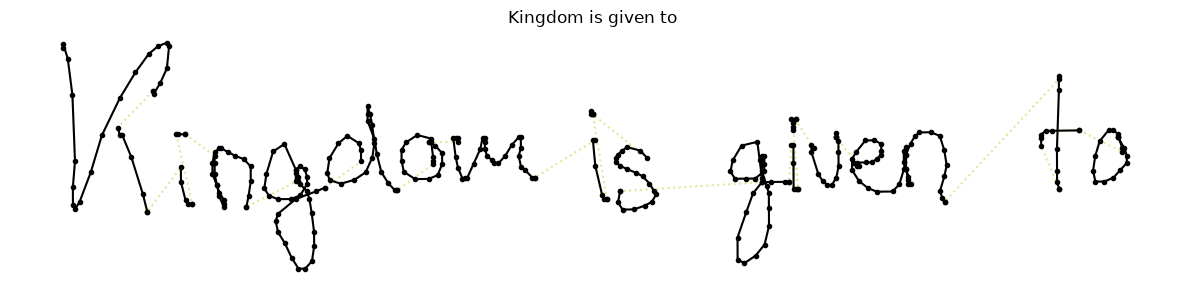

In [8]:
# A visual quick sense check to see if everything looks as it should

idx = 4000

draw_strokes(strokes_data[idx], texts[idx])

# Preprocess Data

Our aim is to train a model that takes a sequence of characters (typically English) and output the pen strokes needed to 'write' them.

In order to prepare the data for training we need to:

1. Shuffle the data.
2. Normalize the strokes.
3. Create the decoder inputs / outputs
4. Pad the strokes so that they of equal length.
5. Split the data into train and validation sets.
6. Vectorise the texts

### Shuffle and Split the Data

In [9]:
# A seed value for shuffling for consistency

seed = 42

In [10]:
# Shuffle and split the strokes and texts

strokes_train, strokes_val, texts_train, texts_val = train_test_split(
    strokes_data, texts, test_size=0.1, random_state=seed
)

assert len(strokes_train) == len(texts_train)
assert len(strokes_val) == len(texts_val)

### Stroke Normalization

In [11]:
# Ignore the synthetic EOS values, and only calculate the mean and standard
# deviation on the training samples. Include the SOS, as it's a valid coordinate (the origin)

c = np.concat([strokes[:-1] for strokes in strokes_train], axis=0)

# mean of x and y values separately
mean_dx = np.mean(c[:, 0])
mean_dy = np.mean(c[:, 1])

# to maintain uniform physical scale in all directions
# we calculate a combined std dev
std_dev = np.std(c[:, :2])

assert np.isfinite(std_dev) and std_dev > 0

print("Mean dx:\t", mean_dx)
print("Mean dy:\t", mean_dy)
print("Standard dev:\t", std_dev)

Mean dx:	 1.8000379
Mean dy:	 0.06783999
Standard dev:	 8.970526


In [12]:
def normalize_strokes(strokes: np.ndarray) -> np.ndarray:
    x_norm = (strokes[..., 0] - mean_dx) / std_dev
    y_norm = (strokes[..., 1] - mean_dy) / std_dev
    return np.column_stack((x_norm, y_norm, strokes[:, 2:]))

def denormalize_strokes(strokes_norm: np.ndarray) -> np.ndarray:
    x = (strokes_norm[..., 0] * std_dev) + mean_dx
    y = (strokes_norm[..., 1] * std_dev) + mean_dy
    return np.column_stack((x, y, strokes_norm[:, 2:]))

In [13]:
strokes_train_norm = [
    normalize_strokes(strokes) for strokes in strokes_train
]

strokes_val_norm = [
    normalize_strokes(strokes) for strokes in strokes_val
]

### Decoder Inputs/Outputs

In [14]:
# Shift the sequence of strokes by one, so that the model predicts the next stroke at every
# timestep

X_train_dec = []
X_val_dec = []

y_train = []
y_val = []

for strokes in strokes_train_norm:
    # inputs = SOS + strokes
    X_train_dec.append(strokes[:-1])
    
    # outputs = strokes + EOS
    y_train.append(strokes[1:])


for strokes in strokes_val_norm:
    # inputs = SOS + strokes
    X_val_dec.append(strokes[:-1])
    
    # outputs = strokes + EOS
    y_val.append(strokes[1:])

### Padding

In [15]:
# we subtract one here because we're removing one element from each array
# (either the SOS or EOS token)

max_stroke_length = len(max(strokes_data, key=len)) - 1

In [16]:
# the value used to pad/mask sequences to equal lengths

mask_value = -999.0

In [17]:
# Converts each to arrays of shape (N, 1189, 5)

def pad_strokes(array: np.ndarray) -> np.ndarray:
    return tf.keras.preprocessing.sequence.pad_sequences(
        array,
        padding='post',
        maxlen=max_stroke_length,
        value=mask_value,
        dtype='float32'
    )

In [18]:
X_train_dec = pad_strokes(X_train_dec)
X_val_dec = pad_strokes(X_val_dec)

y_train = pad_strokes(y_train)
y_val = pad_strokes(y_val)

assert X_train_dec.shape == y_train.shape
assert X_val_dec.shape == y_val.shape

In [19]:
print("Training set shape:\t", X_train_dec.shape)
print("Validation set shape:\t", X_val_dec.shape)

Training set shape:	 (4671, 1189, 5)
Validation set shape:	 (520, 1189, 5)


### Text vectorisation

In [20]:
# Gather all characters in the texts

alphabet = set()
max_text_length = float('-inf')

for text in texts:
    for char in text:
        alphabet.add(char)

    max_text_length = max(max_text_length, len(text))

print("Number of unique characters: ", len(alphabet))
print("Longest text length: ", max_text_length)

Number of unique characters:  79
Longest text length:  64


In [21]:
# Create a TextVecotrisation layer for the inputs

alphabet_size = len(alphabet)

text_vectorisation = tf.keras.layers.TextVectorization(
    # alphabet + 2 because we need space for padding and unknown tokens
    max_tokens=alphabet_size + 2,
    standardize=None,
    output_sequence_length=max_text_length,
    split="character"
)

text_vectorisation.adapt(texts)

### Encoder Inputs

In [22]:
X_train_enc = tf.constant(texts_train)
X_val_enc = tf.constant(texts_val)

assert len(X_train_enc) == len(X_train_dec) == len(y_train)
assert len(X_val_enc) == len(X_val_dec) == len(y_val)

# Build Model

The model is an encoder-decoder model made up of LSTMs and Luong attention.

It predicts a K mixture components (bell curves) to generate for each target, and computes Negative Log-Likelihood loss for 2D MDN stroke trajectory coordinates (where the next stroke should go).

For the pen state (pen up/down and EOS) it computes Categorical Cross-Entropy loss.

In [23]:
# Number of mixture components (bell curves) to generate for each target

K = 20

In [24]:
def loss_function(y_true, y_pred):
    """
    Computes combined Negative Log-Likelihood loss for 2D MDN trajectory
    coordinates and Categorical Cross-Entropy loss for pen up/down and EOS.
    """
    # -------------------------------------------------------------------------
    # 1. Unpack Ground Truth Targets (batch, time, 1)
    # -------------------------------------------------------------------------
    target_x = y_true[:, :, 0:1]  # True horizontal offset (dx)
    target_y = y_true[:, :, 1:2]  # True vertical offset (dy)
    target_pen_state = y_true[:, :, 2:]  # True pen state [down, up, finished]

    # -------------------------------------------------------------------------
    # 2. Unpack Predicted MDN Parameters (batch, time, K)
    # -------------------------------------------------------------------------

    # pi: Component probabilities
    pi = y_pred[:, :, 0:K]

    # mu: Center locations for dx and dy
    mu_x = y_pred[:, :, K : 2 * K]
    mu_y = y_pred[:, :, 2 * K : 3 * K]

    # sigma: Spread/std-dev along dx and dy (> 0)
    sigma_x = y_pred[:, :, 3 * K : 4 * K]
    sigma_y = y_pred[:, :, 4 * K : 5 * K]

    # rho: Correlation/tilt (-1 to +1)
    rho = y_pred[:, :, 5 * K : 6 * K]

    # Predicted pen state prob (batch, time, 1)
    pred_pen_state = y_pred[:, :, 6 * K :]

    # -------------------------------------------------------------------------
    # 3. Compute Bivariate Gaussian Likelihood (Coordinates)
    # -------------------------------------------------------------------------
    # Normalized deviations from predicted centers
    norm_x = (target_x - mu_x) / sigma_x
    norm_y = (target_y - mu_y) / sigma_y

    # Bound (1 - rho^2) above zero to prevent sqrt(0) or division by zero
    one_minus_rho_sq = tf.clip_by_value(1.0 - tf.square(rho), 1e-5, 1.0)

    # Exponent z includes cross-term for correlation-driven tilt
    z = (
        tf.square(norm_x) + tf.square(norm_y) - (2.0 * rho * norm_x * norm_y)
    ) / one_minus_rho_sq

    # Bivariate Normal PDF evaluation
    denom = 2.0 * np.pi * sigma_x * sigma_y * tf.sqrt(one_minus_rho_sq)
    pdf = tf.exp(-0.5 * z) / denom

    # Weighted probability density sum across mixture components
    # Clip probability to a lower bound to prevent it from zerowing out.
    total_prob_density = tf.reduce_sum(pi * pdf, axis=-1, keepdims=True)
    total_prob_density = tf.clip_by_value(total_prob_density, 1e-12, np.inf)

    mdn_loss = -tf.math.log(total_prob_density)

    # -------------------------------------------------------------------------
    # 4. Compute Categorical Cross-Entropy (Pen State)
    # -------------------------------------------------------------------------
    pen_loss = tf.keras.losses.categorical_crossentropy(target_pen_state, pred_pen_state)
    pen_loss = tf.expand_dims(pen_loss, axis=-1)  # Reshape back to (batch, time, 1)

    # Scale pen loss by 3.0 to force the model to learn rare pen lifts
    pen_loss *= 3

    # -------------------------------------------------------------------------
    # 5. Apply the mask and calculate the mean loss
    # -------------------------------------------------------------------------

    # Create a binary mask (1.0 for valid steps, 0.0 for padded steps)
    # We don't penalize the model for not predicting -999.0
    mask = tf.cast(
        tf.math.not_equal(target_x, mask_value),
        tf.float32
    )

    # Keep the coordinate loss and mask out the EOS from the stroke predictions
    # Removes an unnecessary coordinate-learning objective at EOS
    coordinate_mask = tf.cast(
        tf.equal(y_true[:, :, 4:5], 0),
        tf.float32,
    )

    # Remove coordinate loss at EOS, but retain its pen-state loss.
    combined_loss = (coordinate_mask * mdn_loss) + pen_loss

    # Remove all loss at padded timesteps
    masked_loss = combined_loss * mask

    # Sum the valid losses and divide by the exact number of valid timesteps
    sum_loss = tf.reduce_sum(masked_loss)
    num_steps = tf.maximum(tf.reduce_sum(mask), 1.0) # Prevent division by zero

    return sum_loss / num_steps

### Encoder

The encoder takes in text vectors, and passes the hidden state of a bidrectional LSTM to the decoder.

In [25]:
# The number of units in the LSTMs in the encoder AND half the number of units
# in the LSTMs in the decoder.

encoder_units = 256

In [26]:
# ---------------------------------------- inputs and vectorisation

encoder_input_layer = tf.keras.layers.Input(shape=[], dtype=tf.string)
encoder_vectorised_inputs = text_vectorisation(encoder_input_layer)

# ---------------------------------------- embedding layer

encoder_embedding_layer = tf.keras.layers.Embedding(
    input_dim=text_vectorisation.vocabulary_size(),
    output_dim=alphabet_size,
    mask_zero=True
)
encoder_embeddings = encoder_embedding_layer(encoder_vectorised_inputs)

# We pass this mask into the attention block in the LSTMAttenionCell of the
# decoder.
encoder_mask = encoder_embedding_layer.compute_mask(
    encoder_vectorised_inputs
)

# ---------------------------------------- hidden layer(s)

encoder_lstm = tf.keras.layers.Bidirectional(
    tf.keras.layers.LSTM(encoder_units, return_state=True, return_sequences=True)
)
encoder_outputs, forward_h, forward_c, backward_h, backward_c = encoder_lstm(
    encoder_embeddings
)

# A bidrectional LSTM will return four states (two short-term, two long-term)
# thus we need to concatenate the two short-term states and the two long-term
# states
encoder_state = [
    tf.keras.layers.Concatenate(axis=-1)([forward_h, backward_h]),
    tf.keras.layers.Concatenate(axis=-1)([forward_c, backward_c])
]

### Decoder

The decoder is composed of LSTM cells with attention on the encoder outputs.

In [27]:
class LSTMAttentionCell(tf.keras.layers.Layer):

    def __init__(self, units, **kwargs):
        super().__init__(**kwargs)
        self.units = units

        self.state_size = [
            units,                          # Decoder hidden state
            units,                          # Decoder cell state
            tf.TensorShape([None, units]),  # Encoder outputs
            tf.TensorShape([None])          # Encoder mask
        ]

        self.output_size = units

        self.lstm = tf.keras.layers.LSTMCell(units=units)
        self.attention = tf.keras.layers.Attention()
        self.concatenate_layer = tf.keras.layers.Concatenate(axis=-1)

    def call(self, inputs, states, training=None):
        """
        We overwrite the call method to add attention to the encoder outputs
        BEFORE running it through our LSTM.

        In order to achieve this we squeeze additional information into the
        state array. This state includes:

            (1) The LSTM state of the previous time step (as normal)
            (2) The encoder outputs
            (3) A mask of the encoder inputs
        """

        # Unpack the 4 states - self.state_size for definition
        hidden_state, cell_state, encoder_outputs, mask_state = states

        # The attention layer expects 3D inputs, so we expand the hidden state
        query = tf.expand_dims(hidden_state, axis=1)

        # RNN may cast initial states to its floating-point compute dtype.
        # Attention needs a boolean mask, so convert it back here.
        encoder_mask = tf.cast(mask_state, tf.bool)

        attention_outputs = self.attention(
            inputs=[query, encoder_outputs],
            mask=[None, encoder_mask],
            training=training,
        )

        # Squeeze the attention outputs back to 2D
        attention_outputs = tf.squeeze(attention_outputs, axis=1)

        # concatenate the attention outputs with the inputs
        lstm_inputs = self.concatenate_layer([attention_outputs, inputs])

        # LSTMCell returns (output, [hidden_state, cell_state])
        lstm_outputs, new_states = self.lstm(lstm_inputs, states=[hidden_state, cell_state])

        # Return the output, the new LSTM states and the additional passthrough
        # values
        return lstm_outputs, [
            new_states[0],
            new_states[1],
            encoder_outputs,
            mask_state
        ]

In [28]:
class LSTM(tf.keras.layers.Layer):

    def __init__(self, units, **kwargs):
        super().__init__(**kwargs)
        self.units = units
        
        self.state_size = [
            units,                          # Decoder LSTM hidden state
            units,                          # Decoder LSTM cell state
            tf.TensorShape([None, units]),  # Encoder outputs
            tf.TensorShape([None])          # Encoder mask
        ]
        self.output_size = units
        self.lstm = tf.keras.layers.LSTMCell(units=units)

    def call(self, inputs, states, training=None):
        """
        Args:

            inputs: the pen stroke for this ONE timestep.
                
            states: At every later step it is the list we returned 
                at the end of the previous step.
        """

        # Unpack the 4 states - self.state_size for definition
        hidden_state, cell_state, encoder_outputs, encoder_mask = states

        # LSTMCell returns (output, [hidden_state, cell_state])
        outputs, new_states = self.lstm(
            inputs, 
            states=[hidden_state, cell_state],
        )

        # Return the new LSTM states and the additional passthrough values
        return outputs, [
            new_states[0],
            new_states[1],
            encoder_outputs,
            mask_state
        ]

In [33]:
class GaussianAttention(tf.keras.layers.Layer):

    def __init__(self, num_gaussians: int = 1, step_scale: float = 1 / 25, **kwargs):
        super().__init__(**kwargs)
        self.num_gaussians = num_gaussians

        # Shrinks the initial kappa step so the window doesn't race off the
        # end of the text early in training
        self.step_scale = step_scale

        # Predict 3 values per Gaussian: alpha, beta and the kappa step
        self.output_layer = tf.keras.layers.Dense(3 * num_gaussians)

    def call(self, query, kappa, values, mask):
        """
        Args:
            query:  (B, units) the DECODER's hidden state at this pen step.
                    This drives the window.
            kappa:  (B, K) window positions from the previous pen step.
            values: (B, U, D) what the window reads. Either one-hot
                    characters (D = vocab size) or encoder outputs
                    (D = 2 * encoder_units).
            mask:   (B, U) 1.0 for real characters, 0.0 for padding.

        Returns:
            context: (B, D) the "current letter" vector
            kappa:   (B, K) the updated window positions
            phi:     (B, U) the window weights, handy for plotting
        """
        # (B, 3K) raw numbers -> exp makes them positive -> three (B, K)
        params = tf.math.exp(self.output_layer(query))
        alpha, beta, kappa_step = tf.split(params, 3, axis=-1)

        # Move the window forward (kappa_step is always positive)
        kappa = kappa + kappa_step * self.step_scale

        # Character positions [0, 1, ..., U-1]
        u = tf.range(tf.shape(values)[1], dtype=tf.float32)  # (U,)

        # Every Gaussian against every position: (B, K, 1) vs (U,) -> (B, K, U)
        bumps = self.phi(alpha[:, :, None], beta[:, :, None], kappa[:, :, None], u)

        # Add the K bumps together, then zero out padded characters
        phi = tf.reduce_sum(bumps, axis=1) * mask  # (B, U)

        # Weighted sum of the character vectors
        context = tf.einsum("bu,bud->bd", phi, values)  # (B, D)

        return context, kappa, phi

    @staticmethod
    def phi(alpha, beta, kappa, u):
        return alpha * tf.math.exp(-beta * tf.square(kappa - u))

In [28]:
# We output the components of an MDN, however, we add these costants to stop the 
# model from reward hacking

sigma_delta: float = 1e-2
rho_scaling_fator: float = 0.95

In [29]:
# ---------------------------------------- inputs and masking

decoder_input_layer = tf.keras.layers.Input(shape=(None, 5))

decoder_masking_layer = tf.keras.layers.Masking(mask_value=mask_value)(decoder_input_layer)

# ---------------------------------------- hidden layer(s)

# Two LSTM + attention layers

initial_state = [
    encoder_state[0],
    encoder_state[1],
    encoder_outputs,
    encoder_mask
]

x = tf.keras.layers.RNN(
    LSTMAttentionCell(units=encoder_units * 2),
    return_sequences=True,
    return_state=False
)(
    decoder_masking_layer,
    initial_state=initial_state
)

x = tf.keras.layers.RNN(
    LSTMAttentionCell(units=encoder_units * 2),
    return_sequences=True,
    return_state=False
)(
    x,
    initial_state=initial_state
)


# ---------------------------------------- output layers

# pi: mixture component probabilities
pi = tf.keras.layers.Dense(K, activation="softmax", name="pi")(x)

# mu: means
mu_x = tf.keras.layers.Dense(K, name="mu_x")(x)
mu_y = tf.keras.layers.Dense(K, name="mu_y")(x)

# sigma: standard deviations
sigma_x = tf.keras.layers.Dense(K, activation="softplus", name="sigma_x")(x)

# this prevents the model from reward hacking -- if sigma is almost 1 then
# 1 / sigma tends to infinity
sigma_x = tf.keras.layers.Lambda(lambda s: s + sigma_delta, name="sigma_x_floored")(
    sigma_x
)

sigma_y = tf.keras.layers.Dense(K, activation="softplus", name="sigma_y")(x)

# this prevents the model from reward hacking -- if sigma is almost 1 then
# 1 / sigma tends to infinity
sigma_y = tf.keras.layers.Lambda(lambda s: s + sigma_delta, name="sigma_y_floored")(
    sigma_y
)

# rho: correlation
rho = tf.keras.layers.Dense(K, activation="tanh", name="rho")(x)
# this prevents the model from reward hacking -- if rho is almost 1 then
# 1 / (1 - rho^2) tends to infinity
rho = tf.keras.layers.Lambda(lambda r: r * rho_scaling_fator, name="rho_scaled")(rho)

# pen state: predict the probabilities pen: [down, up, finished]
pen_state = tf.keras.layers.Dense(
    3, activation="softmax", name="pen_state"
)(x)

decoder_output_layer = tf.keras.layers.concatenate(
    [pi, mu_x, mu_y, sigma_x, sigma_y, rho, pen_state], axis=-1
)

/Users/jacob/github.com/jda5/handwriting-synthesis/.venv/lib/python3.13/site-packages/keras/src/layers/layer.py:431: UserWarning: `build()` was called on layer 'lstm_attention_cell', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/Users/jacob/github.com/jda5/handwriting-synthesis/.venv/lib/python3.13/site-packages/keras/src/layers/layer.py:431: UserWarning: `build()` was called on layer 'lstm_attention_cell_1', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/Users/jacob/github.com/jda5/handwriting-synth

### Model

In [30]:
model = tf.keras.Model(
    inputs=[encoder_input_layer, decoder_input_layer],
    outputs=decoder_output_layer
)

optimizer = tf.keras.optimizers.Adam(learning_rate=1e-4, clipnorm=1.0)

model.compile(loss=loss_function, optimizer=optimizer)

# Training

In [31]:
# Save the model weights after every epoch. Also save the preprocessing state.

checkpoint_filepath = CHECKPOINTS_DIR / datetime.now().strftime("%Y-%m-%dT%H-%M-%S")
checkpoint_filepath.mkdir()

model_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=checkpoint_filepath / 'model.weights.h5',
    save_weights_only=True,
    save_best_only=True,
    monitor="val_loss",
    mode="min",
)

with open(checkpoint_filepath / "preprocessing.json", "w") as file:
    json.dump(
        {
            "mean_dx": float(mean_dx), 
            "mean_dy": float(mean_dy), 
            "std_dev": float(std_dev),
            "vocabulary": text_vectorisation.get_vocabulary(),
            "max_text_length": max_text_length, 
            "max_stroke_length": max_stroke_length,
        }, file
    )

In [32]:
# Stop training when there are no further improvements

early_stopping = tf.keras.callbacks.EarlyStopping(
    patience=5, restore_best_weights=True
)

In [33]:
history = model.fit(
    x=(X_train_enc, X_train_dec),
    y=y_train,
    epochs=150,
    validation_data=((X_val_enc, X_val_dec), y_val),
    callbacks=[
        model_checkpoint,
        early_stopping
    ]
)

Epoch 1/150
2/2 ━━━━━━━━━━━━━━━━━━━━ 26s 14s/step - loss: 5.5085 - val_loss: 5.1533
Epoch 2/150
2/2 ━━━━━━━━━━━━━━━━━━━━ 22s 12s/step - loss: 5.1332 - val_loss: 4.7625
Epoch 3/150
2/2 ━━━━━━━━━━━━━━━━━━━━ 19s 11s/step - loss: 4.7293 - val_loss: 4.3179
Epoch 4/150


KeyboardInterrupt: 

# Exercises

In [ ]:
import matplotlib.pyplot as plt

In [34]:
def phi(u, alpha, beta, kappa):
    return alpha * tf.math.exp(-beta * tf.square(kappa - u))

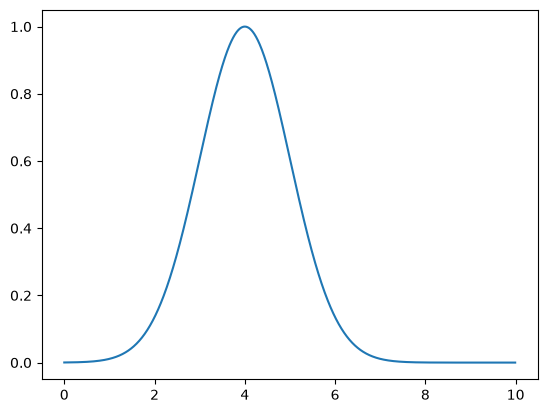

In [46]:
u = tf.range(0, 10, 0.01)
alpha = 1.0
beta = 0.5
kappa = 4

plt.plot(u, phi(u, alpha, beta, kappa))
plt.show()

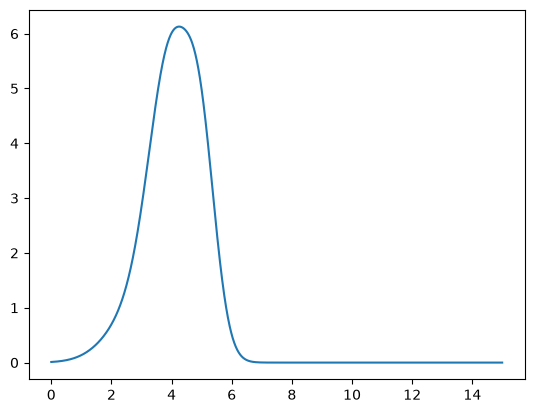

In [92]:
u = tf.range(0, 15, 0.01)

alpha = tf.constant([1.0, 5.0, 3.0])
beta  = tf.constant([0.5, 1.0, 2.0])
kappa = tf.constant([3.0, 4.0, 5.0])

# Turn each (K,) into a column (K, 1), so it broadcasts against u (U,)
bumps = phi(u, alpha[:, None], beta[:, None], kappa[:, None])   # (K, U)

# One row per Gaussian -> sum the rows (axis 0 is K)
values = tf.reduce_sum(bumps, axis=0)

plt.plot(u, values)
plt.show()

In [ ]:
class GaussianWindow(tf.keras.layers.Layer):
    """Soft, monotonic attention over the text. Graves (2013), parameterised as
    GMMv2b from Battenberg et al. (2020)."""

    def __init__(self, num_components=10, initial_step=0.05, **kwargs):
        super().__init__(**kwargs)
        self.num_components = num_components
        self.step_offset = np.log(np.expm1(initial_step))  # softplus(offset) == initial_step
        self.params = tf.keras.layers.Dense(3 * num_components)

    def call(self, query, kappa, values, text_mask):
        logits, raw_sigma, raw_step = tf.split(self.params(query), 3, axis=-1)  # each (B, K)
        weight = tf.nn.softmax(logits)
        sigma = tf.nn.softplus(raw_sigma)
        kappa = kappa + tf.nn.softplus(raw_step + self.step_offset)

        u = tf.range(tf.shape(values)[1], dtype=tf.float32)                   # (U,)
        z = (u - kappa[..., None]) / sigma[..., None]                          # (B, K, U)
        density = tf.exp(-0.5 * tf.square(z)) / (sigma[..., None] * np.sqrt(2 * np.pi))
        phi = tf.reduce_sum(weight[..., None] * density, axis=1) * text_mask  # (B, U)

        context = tf.einsum("bu,bud->bd", phi, values)                        # (B, D)
        return context, kappa, phi